# Ejercicio 8: Máquinas de vectores soporte (SVM)

**Tópicos Selectos en Aprendizaje Maquinal — TP N°1: Algoritmos para Reconocimiento de Patrones**

La consigna pide desarrollar los incisos **"a mano"**. Por eso, en este notebook **toda la resolución está escrita en las celdas de texto**, con cada cuenta explícita. El código se usa solamente para:

- **graficar** (datos, función de decisión, funciones duales), y
- una **verificación independiente** al final de cada problema (con `scikit-learn`), que no forma parte de la resolución.

| Problema | Datos | Qué se pide |
|:--|:--|:--|
| **1** (Fig. 3) | $x_1=-1$ (clase 1), $x_2=0$ y $x_3=1$ (clase 2): **linealmente separable** | Restricciones, dual, $\alpha_i$, función de decisión y vectores soporte |
| **2** (Fig. 4) | $x_1=-1$ (clase 1), $x_2=0$ (clase 2), $x_3=1$ (clase 1): **no separable linealmente**; núcleo $k(x,x')=(xx'+1)^2$ | Dual, $C$ y $\alpha_i$, función de decisión y vectores soporte |

**Contenido**

1. [Teoría: de qué se trata una SVM](#1.-Teoría)
2. [Problema 1: caso linealmente separable](#2.-Problema-1:-caso-linealmente-separable)
3. [Problema 2: caso no lineal con núcleo polinomial](#3.-Problema-2:-caso-no-lineal-con-núcleo-polinomial)
4. [Conclusiones](#4.-Conclusiones)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
C1, C2 = "tab:red", "tab:blue"     # clase 1 (círculo rojo) y clase 2 (cuadrado azul), como en las figuras de la guía

---
## 1. Teoría

### 1.1 Convención de etiquetas

Las figuras de la guía muestran dos clases. Se adopta
$$
\text{clase 1} \;\Rightarrow\; y=-1 \;(\text{círculo rojo}),\qquad \text{clase 2} \;\Rightarrow\; y=+1 \;(\text{cuadrado azul}).
$$
Si se eligiera la convención contraria cambiarían los signos de $w$ y $b$ (la función de decisión pasaría a ser $-f$), pero los $\alpha_i$, los vectores soporte y la frontera serían los mismos.

### 1.2 SVM de margen duro (caso separable)

Se busca el hiperplano $f(\mathbf{x}) = \mathbf{w}\cdot\mathbf{x}+b = 0$ que separa las clases con **margen máximo**. Las muestras deben quedar del lado correcto y a distancia al menos $1/\|\mathbf{w}\|$:
$$
\min_{\mathbf{w},b}\ \tfrac12\|\mathbf{w}\|^2 \quad\text{sujeto a}\quad y_i(\mathbf{w}\cdot\mathbf{x}_i+b)\ \ge\ 1,\quad i=1,\dots,N.
$$
(El margen vale $2/\|\mathbf{w}\|$, así que maximizarlo equivale a minimizar $\|\mathbf{w}\|^2$.)

### 1.3 Dual

Se introduce un multiplicador $\alpha_i\ge0$ por cada restricción y se escribe el lagrangiano
$$
L(\mathbf{w},b,\boldsymbol\alpha)=\tfrac12\|\mathbf{w}\|^2-\sum_i\alpha_i\big[y_i(\mathbf{w}\cdot\mathbf{x}_i+b)-1\big].
$$
Las condiciones de estacionariedad respecto de las variables primales dan:
$$
\frac{\partial L}{\partial \mathbf{w}}=0\ \Rightarrow\ \mathbf{w}=\sum_i\alpha_i y_i\mathbf{x}_i,\qquad
\frac{\partial L}{\partial b}=0\ \Rightarrow\ \sum_i\alpha_i y_i=0.
$$
Sustituyendo en $L$ se obtiene el **problema dual**, que depende solo de los $\alpha_i$ y de los productos escalares entre muestras:
$$
\boxed{\ \max_{\boldsymbol\alpha}\ W(\boldsymbol\alpha)=\sum_i\alpha_i-\frac12\sum_{i,j}\alpha_i\alpha_j\,y_iy_j\,(\mathbf{x}_i\cdot\mathbf{x}_j)\quad\text{s.a.}\quad \alpha_i\ge0,\ \ \sum_i\alpha_iy_i=0.\ }
$$

### 1.4 Condiciones KKT, vectores soporte y función de decisión

En el óptimo se cumple la **complementariedad**: $\alpha_i\,[\,y_i(\mathbf{w}\cdot\mathbf{x}_i+b)-1\,]=0$. Por lo tanto:

- si $\alpha_i>0$, la restricción está **activa** ($y_if(\mathbf{x}_i)=1$): la muestra está justo sobre el margen y es un **vector soporte**;
- si $y_if(\mathbf{x}_i)>1$, entonces $\alpha_i=0$: la muestra no influye en la solución.

El $b$ se obtiene de cualquier vector soporte, $b=y_s-\mathbf{w}\cdot\mathbf{x}_s$ (con $y_s=\pm1$), y la función de decisión es
$$
f(\mathbf{x})=\sum_i\alpha_iy_i\,(\mathbf{x}_i\cdot\mathbf{x})+b,\qquad \hat y=\operatorname{sign} f(\mathbf{x}).
$$

### 1.5 Núcleos y margen blando

- **Núcleo (*kernel trick*):** como el dual y $f$ solo usan productos escalares, se los puede reemplazar por $k(\mathbf{x}_i,\mathbf{x}_j)=\varphi(\mathbf{x}_i)\cdot\varphi(\mathbf{x}_j)$, que equivale a trabajar con un hiperplano en el espacio transformado $\varphi(\mathbf{x})$ sin calcular $\varphi$ explícitamente.
- **Margen blando:** si no hay un hiperplano que separe sin errores, se permiten violaciones $\xi_i\ge0$:
$$
\min_{\mathbf{w},b,\boldsymbol\xi}\ \tfrac12\|\mathbf{w}\|^2+C\sum_i\xi_i\quad\text{s.a.}\quad y_i(\mathbf{w}\cdot\varphi(\mathbf{x}_i)+b)\ge1-\xi_i,\ \ \xi_i\ge0.
$$
El dual es el mismo, pero con la **cota superior** $0\le\alpha_i\le C$. El parámetro $C$ regula el compromiso entre margen ancho y errores: $C$ grande se parece al margen duro; $C$ chico tolera más violaciones. Además, la complementariedad se extiende así:
$$
\alpha_i=0\Rightarrow y_if(\mathbf{x}_i)\ge1,\qquad 0<\alpha_i<C\Rightarrow y_if(\mathbf{x}_i)=1\ (\xi_i=0),\qquad \alpha_i=C\Rightarrow y_if(\mathbf{x}_i)\le1.
$$

---
## 2. Problema 1: caso linealmente separable

**Datos** (Fig. 3):

| $i$ | $x_i$ | clase | $y_i$ |
|:-:|:-:|:-:|:-:|
| 1 | $-1$ | 1 | $-1$ |
| 2 | $0$ | 2 | $+1$ |
| 3 | $1$ | 2 | $+1$ |

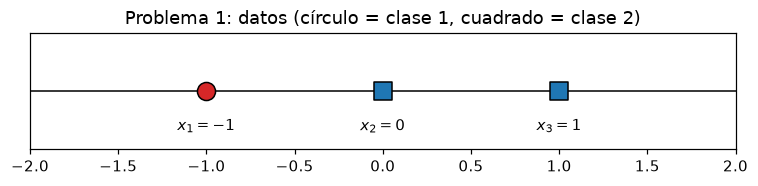

In [2]:
x = np.array([-1.0, 0.0, 1.0]); y = np.array([-1, 1, 1])
fig, ax = plt.subplots(figsize=(7, 1.8))
ax.axhline(0, color="k", lw=1)
for xi, yi in zip(x, y):
    ax.scatter(xi, 0, marker="o" if yi < 0 else "s", s=140, c=C1 if yi < 0 else C2, edgecolor="k", zorder=3)
    ax.annotate(f"$x_{{{list(x).index(xi)+1}}}={xi:g}$", (xi, 0), xytext=(0, -26), textcoords="offset points", ha="center")
ax.set(xlim=(-2, 2), ylim=(-0.5, 0.5), yticks=[], title="Problema 1: datos (círculo = clase 1, cuadrado = clase 2)")
ax.grid(False); plt.tight_layout(); plt.show()

### a) Restricciones

Con $w,b\in\mathbb{R}$ (problema unidimensional), la restricción $y_i(wx_i+b)\ge1$ para cada muestra es:

$$
\begin{aligned}
i=1:&\quad y_1(wx_1+b)=-\,(-w+b)\ge1 \;\Longrightarrow\; \boxed{\,w-b\ge1\,}\\
i=2:&\quad y_2(wx_2+b)=+\,(0\cdot w+b)\ge1 \;\Longrightarrow\; \boxed{\,b\ge1\,}\\
i=3:&\quad y_3(wx_3+b)=+\,(w+b)\ge1 \;\Longrightarrow\; \boxed{\,w+b\ge1\,}
\end{aligned}
$$

El problema primal es entonces $\min\ \tfrac12w^2$ sujeto a esas tres inecuaciones.

**Comprobación rápida del primal.** De $b\ge1$ y $w-b\ge1$ se deduce $w\ge1+b\ge2$. Como se quiere minimizar $w^2$, el mínimo es $w=2$, que se obtiene con $b=1$ (ambas cotas se vuelven igualdades). La tercera inecuación se verifica holgadamente: $w+b=3\ge1$. Es decir, $w=2$, $b=1$. Más abajo se obtendrá lo mismo por el camino dual.

### b) Problema dual

Se necesita $x_i x_j$ y $y_iy_j$ para armar el término cuadrático:

$$
[x_ix_j]=\begin{pmatrix}1&0&-1\\0&0&0\\-1&0&1\end{pmatrix},\qquad
[y_iy_j]=\begin{pmatrix}1&-1&-1\\-1&1&1\\-1&1&1\end{pmatrix}.
$$

La suma doble $\sum_{i,j}\alpha_i\alpha_jy_iy_jx_ix_j$ solo tiene términos con $i,j\in\{1,3\}$ (porque $x_2=0$):

$$
\alpha_1^2\,(1)(1)\;+\;\alpha_3^2\,(1)(1)\;+\;2\alpha_1\alpha_3\,\underbrace{y_1y_3}_{-1}\underbrace{x_1x_3}_{-1}
=\alpha_1^2+\alpha_3^2+2\alpha_1\alpha_3=(\alpha_1+\alpha_3)^2.
$$

El **problema dual** es entonces

$$
\boxed{\;\max_{\boldsymbol\alpha}\ W(\boldsymbol\alpha)=\alpha_1+\alpha_2+\alpha_3-\tfrac12(\alpha_1+\alpha_3)^2\quad\text{s.a.}\quad -\alpha_1+\alpha_2+\alpha_3=0,\ \ \alpha_1,\alpha_2,\alpha_3\ge0.\;}
$$

### c) Valores de $\alpha_i$

**Paso 1: eliminar $\alpha_2$ con la restricción de igualdad.** De $-\alpha_1+\alpha_2+\alpha_3=0$ resulta $\alpha_2=\alpha_1-\alpha_3$, y la condición $\alpha_2\ge0$ obliga a $\alpha_3\le\alpha_1$. Entonces $\alpha_1+\alpha_2+\alpha_3=2\alpha_1$ y

$$
W(\alpha_1,\alpha_3)=2\alpha_1-\tfrac12(\alpha_1+\alpha_3)^2,\qquad \text{con } 0\le\alpha_3\le\alpha_1.
$$

**Paso 2: derivadas parciales.**

$$
\frac{\partial W}{\partial\alpha_1}=2-(\alpha_1+\alpha_3),\qquad
\frac{\partial W}{\partial\alpha_3}=-(\alpha_1+\alpha_3).
$$

**Paso 3: analizar $\alpha_3$.** Mientras $\alpha_1+\alpha_3>0$, la derivada respecto de $\alpha_3$ es **negativa**: $W$ decrece al aumentar $\alpha_3$. Como $\alpha_3\ge0$, el máximo se alcanza **en el borde** $\alpha_3=0$ (no hay punto estacionario interior: $\partial W/\partial\alpha_3=0$ solo se cumple en $\alpha_1=\alpha_3=0$, y allí $\partial W/\partial\alpha_1=2\neq0$, así que no es estacionario).

**Paso 4: con $\alpha_3=0$,** $W(\alpha_1)=2\alpha_1-\tfrac12\alpha_1^2$ y $W'(\alpha_1)=2-\alpha_1=0\Rightarrow\alpha_1=2$. Como $W''=-1<0$, es un máximo, con $W=4-2=2$. Finalmente $\alpha_2=\alpha_1-\alpha_3=2$.

$$
\boxed{\;\alpha_1=2,\qquad\alpha_2=2,\qquad\alpha_3=0\;}
$$

**Comprobaciones:**

- Restricción de igualdad: $-2+2+0=0$ ✓.
- Valor del dual: $W=2+2+0-\tfrac12(2+0)^2=2$. Debe coincidir con el valor del primal $\tfrac12w^2=\tfrac12\cdot4=2$ ✓ (dualidad fuerte).
- En la figura de abajo se ve que el máximo está en el borde de la región factible ($\alpha_3=0$).

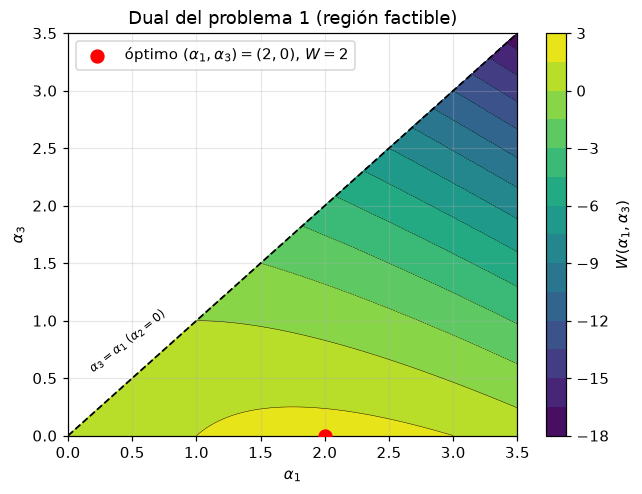

In [3]:
# Gráfico del dual W(α1, α3) = 2α1 - (α1+α3)^2 / 2 en la región factible 0 <= α3 <= α1
a1, a3 = np.meshgrid(np.linspace(0, 3.5, 300), np.linspace(0, 3.5, 300))
W = 2 * a1 - 0.5 * (a1 + a3) ** 2
Wm = np.where(a3 <= a1, W, np.nan)
fig, ax = plt.subplots(figsize=(6, 4.6))
cs = ax.contourf(a1, a3, Wm, levels=18, cmap="viridis")
ax.contour(a1, a3, Wm, levels=18, colors="k", linewidths=0.3)
ax.plot([0, 3.5], [0, 3.5], "k--", lw=1.2); ax.text(0.15, 0.55, r"$\alpha_3=\alpha_1\ (\alpha_2=0)$", color="k", fontsize=8, rotation=38)
ax.scatter(2, 0, c="r", s=70, zorder=5, label=r"óptimo $(\alpha_1,\alpha_3)=(2,0)$, $W=2$")
plt.colorbar(cs, label=r"$W(\alpha_1,\alpha_3)$")
ax.set(xlabel=r"$\alpha_1$", ylabel=r"$\alpha_3$", title="Dual del problema 1 (región factible)", ylim=(0, 3.5))
ax.legend(loc="upper left"); plt.tight_layout(); plt.show()

### d) Función de decisión y vectores soporte

**Vector $w$.** De la estacionariedad, $w=\sum_i\alpha_iy_ix_i$:

$$
w=\alpha_1y_1x_1+\alpha_2y_2x_2+\alpha_3y_3x_3=2\cdot(-1)\cdot(-1)+2\cdot(+1)\cdot0+0=2.
$$

**Vectores soporte.** Son las muestras con $\alpha_i>0$: **$x_1=-1$ y $x_2=0$**. La muestra $x_3=1$ tiene $\alpha_3=0$ y no es vector soporte.

**Sesgo $b$.** Con el vector soporte $x_2=0$ (clase $y_2=+1$): $y_2(wx_2+b)=1\Rightarrow b=1$. Se verifica con el otro vector soporte: $y_1(wx_1+b)=-(2\cdot(-1)+1)=1$ ✓.

**Verificación de KKT para $x_3$:** $y_3(wx_3+b)=2+1=3>1$, es decir, la restricción no está activa, consistente con $\alpha_3=0$ ✓.

**Función de decisión:**

$$
\boxed{\;f(x)=2x+1=\sum_i\alpha_iy_ix_ix+b\;}\qquad\Longrightarrow\qquad
\hat y=\begin{cases}+1\ (\text{clase 2})&x>-\tfrac12\\-1\ (\text{clase 1})&x<-\tfrac12\end{cases}
$$

- **Frontera de decisión:** $f(x)=0\Rightarrow x=-\tfrac12$, justo en el punto medio entre $x_1=-1$ y $x_2=0$.
- **Márgenes:** $f(x)=\pm1\Rightarrow x=-1$ y $x=0$, que son exactamente los dos vectores soporte.
- **Ancho del margen:** $2/\|w\|=2/2=1$ (distancia entre $x=-1$ y $x=0$); a cada lado de la frontera hay $1/\|w\|=\tfrac12$.

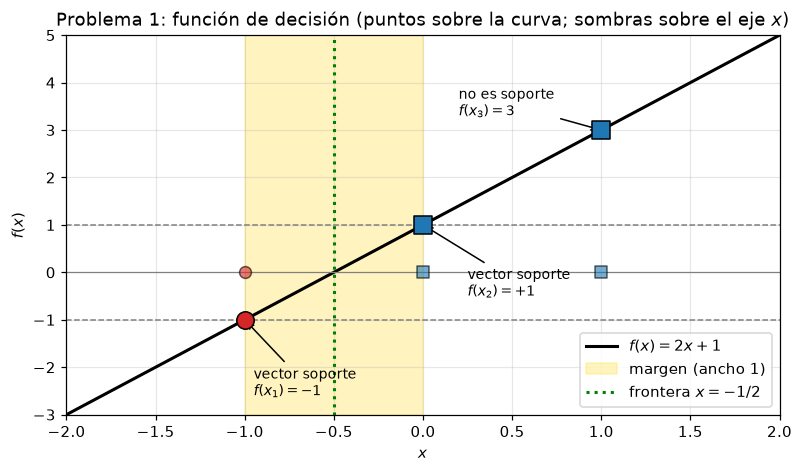

In [4]:
xs = np.linspace(-2, 2, 400)
f = 2 * xs + 1
fig, ax = plt.subplots(figsize=(7.4, 4.4))
ax.plot(xs, f, "k", lw=2, label=r"$f(x)=2x+1$")
ax.axhline(0, color="gray", lw=0.8); ax.axhline(1, color="gray", ls="--", lw=1); ax.axhline(-1, color="gray", ls="--", lw=1)
ax.axvspan(-1, 0, color="gold", alpha=0.25, label="margen (ancho 1)")
ax.axvline(-0.5, color="green", ls=":", lw=2, label=r"frontera $x=-1/2$")
for xi, yi in zip(x, y):
    ax.scatter(xi, 2 * xi + 1, marker="o" if yi < 0 else "s", s=130, c=C1 if yi < 0 else C2, edgecolor="k", zorder=4)
    ax.scatter(xi, 0, marker="o" if yi < 0 else "s", s=60, c=C1 if yi < 0 else C2, edgecolor="k", alpha=0.6, zorder=3)
ax.annotate("vector soporte\n$f(x_1)=-1$", (-1, -1), xytext=(-0.95, -2.6), arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.annotate("vector soporte\n$f(x_2)=+1$", (0, 1), xytext=(0.25, -0.5), arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.annotate("no es soporte\n$f(x_3)=3$", (1, 3), xytext=(0.2, 3.3), arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.set(xlabel="$x$", ylabel="$f(x)$", xlim=(-2, 2), ylim=(-3, 5), title="Problema 1: función de decisión (puntos sobre la curva; sombras sobre el eje $x$)")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

**Verificación independiente (no es parte de la resolución).** Se resuelve el mismo problema con `scikit-learn` (SVM lineal con $C$ muy grande para aproximar el margen duro) y se comparan los resultados con los hallados a mano.

In [5]:
from sklearn.svm import SVC

m = SVC(kernel="linear", C=1e6).fit(x.reshape(-1, 1), y)
print("índices de vectores soporte :", m.support_ + 1, "  (x_1 y x_2)")
print("α_i·y_i (dual_coef_)         :", m.dual_coef_.round(6), "  → α = (2, 2) con y = (-1, +1)")
print("w =", m.coef_.round(6).ravel(), "  b =", m.intercept_.round(6))

índices de vectores soporte : [1 2]   (x_1 y x_2)
α_i·y_i (dual_coef_)         : [[-2.  2.]]   → α = (2, 2) con y = (-1, +1)
w = [2.]   b = [1.]


---
## 3. Problema 2: caso no lineal con núcleo polinomial

**Datos** (Fig. 4): las dos muestras de la clase 1 están a ambos lados de la de clase 2, por lo que **ningún umbral en la recta separa las clases** (cualquier $f(x)=wx+b$ es monótona).

| $i$ | $x_i$ | clase | $y_i$ |
|:-:|:-:|:-:|:-:|
| 1 | $-1$ | 1 | $-1$ |
| 2 | $0$ | 2 | $+1$ |
| 3 | $1$ | 1 | $-1$ |

Núcleo: $k(x,x')=(xx'+1)^2$.

### Qué hace el núcleo

Desarrollando el cuadrado, $k(x,x')=x^2x'^2+2xx'+1=\varphi(x)\cdot\varphi(x')$ con
$$
\varphi(x)=\big(1,\ \sqrt2\,x,\ x^2\big).
$$
Es decir, el núcleo equivale a llevar cada punto a un espacio de **3 dimensiones** y buscar allí un hiperplano. Las imágenes de los datos son:

$$
\varphi(-1)=(1,-\sqrt2,1),\qquad \varphi(0)=(1,0,0),\qquad \varphi(1)=(1,\sqrt2,1).
$$

En ese espacio ya son separables: las muestras de clase 1 tienen $x^2=1$ y la de clase 2 tiene $x^2=0$, de modo que alcanza con mirar la tercera componente.

### Matriz de Gram

Se calcula $K_{ij}=k(x_i,x_j)=(x_ix_j+1)^2$ con $x=(-1,0,1)$:

$$
\begin{aligned}
K_{11}&=(1+1)^2=4, & K_{12}&=(0+1)^2=1, & K_{13}&=(-1+1)^2=0,\\
K_{22}&=(0+1)^2=1, & K_{23}&=(0+1)^2=1, & K_{33}&=(1+1)^2=4,
\end{aligned}
\qquad
\mathbf{K}=\begin{pmatrix}4&1&0\\1&1&1\\0&1&4\end{pmatrix}.
$$

### a) Problema dual

Con margen blando, el dual es
$$
\max_{\boldsymbol\alpha}\ W(\boldsymbol\alpha)=\sum_i\alpha_i-\frac12\sum_{i,j}\alpha_i\alpha_jy_iy_jK_{ij}\quad\text{s.a.}\quad 0\le\alpha_i\le C,\ \ \sum_i\alpha_iy_i=0.
$$

Con $y=(-1,+1,-1)$, los signos $y_iy_j$ son: $y_1y_2=-1$, $y_1y_3=+1$, $y_2y_3=-1$. La suma doble queda

$$
\sum_{i,j}\alpha_i\alpha_jy_iy_jK_{ij}
=4\alpha_1^2+\alpha_2^2+4\alpha_3^2
-2\alpha_1\alpha_2+2\alpha_1\alpha_3\cdot\underbrace{0}_{K_{13}}-2\alpha_2\alpha_3 .
$$

La restricción de igualdad es $-\alpha_1+\alpha_2-\alpha_3=0$. El **problema dual** completo es

$$
\boxed{\;\max_{\boldsymbol\alpha}\ W=\alpha_1+\alpha_2+\alpha_3-\tfrac12\left(4\alpha_1^2+\alpha_2^2+4\alpha_3^2-2\alpha_1\alpha_2-2\alpha_2\alpha_3\right)\ \ \text{s.a.}\ \ \alpha_2=\alpha_1+\alpha_3,\ \ 0\le\alpha_i\le C.\;}
$$

### b) Valores de $\alpha_i$ y de $C$

**Paso 1: eliminar $\alpha_2=\alpha_1+\alpha_3$.** Entonces $\alpha_1+\alpha_2+\alpha_3=2(\alpha_1+\alpha_3)$ y

$$
\alpha_2^2-2\alpha_2(\alpha_1+\alpha_3)=\alpha_2^2-2\alpha_2^2=-\alpha_2^2=-(\alpha_1+\alpha_3)^2,
$$

de modo que la forma cuadrática vale

$$
4\alpha_1^2+4\alpha_3^2-(\alpha_1+\alpha_3)^2=3\alpha_1^2+3\alpha_3^2-2\alpha_1\alpha_3 .
$$

Así,

$$
W(\alpha_1,\alpha_3)=2\alpha_1+2\alpha_3-\tfrac32\alpha_1^2-\tfrac32\alpha_3^2+\alpha_1\alpha_3 .
$$

**Paso 2: punto estacionario** (ignorando por ahora la cota $C$):

$$
\frac{\partial W}{\partial\alpha_1}=2-3\alpha_1+\alpha_3=0,\qquad
\frac{\partial W}{\partial\alpha_3}=2-3\alpha_3+\alpha_1=0 .
$$

Restando las dos ecuaciones: $-3\alpha_1+\alpha_3+3\alpha_3-\alpha_1=0\Rightarrow-4(\alpha_1-\alpha_3)=0\Rightarrow\alpha_1=\alpha_3$. Reemplazando: $2-3\alpha_1+\alpha_1=0\Rightarrow\alpha_1=1$.

La hessiana $\begin{pmatrix}-3&1\\1&-3\end{pmatrix}$ tiene autovalores $-2$ y $-4$ (ambos negativos), así que $W$ es cóncava y el punto es un **máximo global**. Con $\alpha_2=\alpha_1+\alpha_3=2$:

$$
\boxed{\;\alpha_1=1,\qquad\alpha_2=2,\qquad\alpha_3=1\;},\qquad W=2(1+1)-\tfrac32-\tfrac32+1=2 .
$$

**Paso 3: el valor de $C$.** Esta solución es admisible solo si cumple $\alpha_i\le C$ para todo $i$, es decir

$$
\boxed{\;C\ \ge\ \max_i\alpha_i=\alpha_2=2\;}
$$

Para cualquier $C\ge2$ las restricciones de caja no están activas (salvo, en el caso $C=2$, la de $\alpha_2$, que queda justo en la cota con $\xi_2=0$) y la solución del margen blando coincide con la del margen duro: los datos son separables en el espacio de $\varphi$, y con $C$ suficientemente grande no hace falta ninguna violación. Por eso el **menor $C$ que reproduce la solución de margen duro es $C=2$**; en lo que sigue se usa $C\ge2$.

> Más abajo se analiza qué ocurre si $C<2$.

**Comprobaciones:** $-\alpha_1+\alpha_2-\alpha_3=-1+2-1=0$ ✓ y $0<\alpha_i\le C$ ✓.

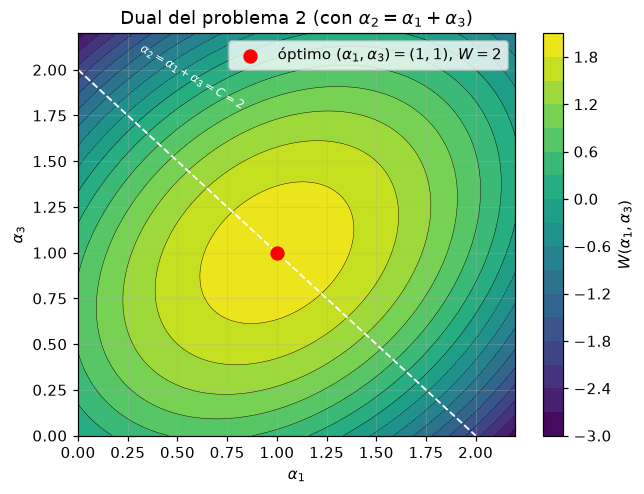

In [6]:
# Dual del problema 2 tras eliminar α2 = α1 + α3:  W(α1, α3). Se dibuja también la zona de la caja [0, C]^3 para C = 2.
a1, a3 = np.meshgrid(np.linspace(0, 2.2, 300), np.linspace(0, 2.2, 300))
W = 2 * a1 + 2 * a3 - 1.5 * a1**2 - 1.5 * a3**2 + a1 * a3
fig, ax = plt.subplots(figsize=(6, 4.6))
cs = ax.contourf(a1, a3, W, levels=18, cmap="viridis"); ax.contour(a1, a3, W, levels=18, colors="k", linewidths=0.3)
ax.plot([0, 2], [2, 0], "w--", lw=1.2); ax.text(0.3, 1.78, r"$\alpha_2=\alpha_1+\alpha_3=C=2$", color="w", fontsize=8, rotation=-30)
ax.scatter(1, 1, c="r", s=70, zorder=5, label=r"óptimo $(\alpha_1,\alpha_3)=(1,1)$, $W=2$")
plt.colorbar(cs, label=r"$W(\alpha_1,\alpha_3)$")
ax.set(xlabel=r"$\alpha_1$", ylabel=r"$\alpha_3$", title="Dual del problema 2 (con $\\alpha_2=\\alpha_1+\\alpha_3$)")
ax.legend(loc="upper right"); plt.tight_layout(); plt.show()

### c) Función de decisión y vectores soporte

**Vectores soporte.** Los tres $\alpha_i$ son positivos, así que **las tres muestras son vectores soporte**.

**Función de decisión.** $f(x)=\sum_i\alpha_iy_ik(x_i,x)+b$. Con $k(x_i,x)=(x_ix+1)^2$:

$$
\begin{aligned}
f(x)&=\alpha_1y_1(1-x)^2+\alpha_2y_2(1)^2+\alpha_3y_3(1+x)^2+b\\
&=-(1-x)^2+2-(1+x)^2+b\\
&=-\big(1-2x+x^2\big)+2-\big(1+2x+x^2\big)+b\\
&=-2x^2+b .
\end{aligned}
$$

(Los términos lineales en $x$ se cancelan por la simetría de los datos.)

**Sesgo $b$.** Se usa un vector soporte con $0<\alpha<C$ y la condición $y_if(x_i)=1$. Con $x_2=0$:

$$
y_2f(0)=1\ \Rightarrow\ f(0)=b=1 .
$$

**Verificación con otro vector soporte** ($x_1=-1$): $f(-1)=-2+1=-1$, y entonces $y_1f(x_1)=(-1)(-1)=1$ ✓. Lo mismo vale para $x_3$ por simetría. Como control adicional, el cálculo directo con $b$ a partir de $x_1$ con la fórmula original: $f(x_1)=\alpha_1y_1K_{11}+\alpha_2y_2K_{21}+\alpha_3y_3K_{31}+b=-4+2+0+b=b-2=-1\Rightarrow b=1$ ✓.

$$
\boxed{\;f(x)=1-2x^2\;}\qquad\Longrightarrow\qquad
\hat y=\begin{cases}+1\ (\text{clase 2})&|x|<\tfrac1{\sqrt2}\approx0.707\\-1\ (\text{clase 1})&|x|>\tfrac1{\sqrt2}\end{cases}
$$

- **Frontera de decisión:** $f(x)=0\Rightarrow x=\pm\tfrac{1}{\sqrt2}$. Son **dos puntos**: en la recta original la región de la clase 2 es el intervalo $(-0.707,\,0.707)$. Esto es algo que ningún clasificador lineal en $x$ puede representar.
- **Márgenes:** $f=+1$ en $x=0$ y $f=-1$ en $x=\pm1$: las tres muestras están exactamente sobre los márgenes.

**Interpretación en el espacio transformado.** El vector de pesos es
$$
\mathbf{w}=\sum_i\alpha_iy_i\varphi(x_i)=-1\,(1,-\sqrt2,1)+2\,(1,0,0)-1\,(1,\sqrt2,1)=(0,\,0,\,-2),
$$
y $f=\mathbf{w}\cdot\varphi(x)+b=-2x^2+1$ ✓. El margen geométrico es $1/\|\mathbf{w}\|=\tfrac12$ a cada lado, y el hiperplano es $x^2=\tfrac12$, es decir, un plano horizontal en la coordenada $z=x^2$: lineal en el espacio transformado, pero **cuadrático en $x$**.

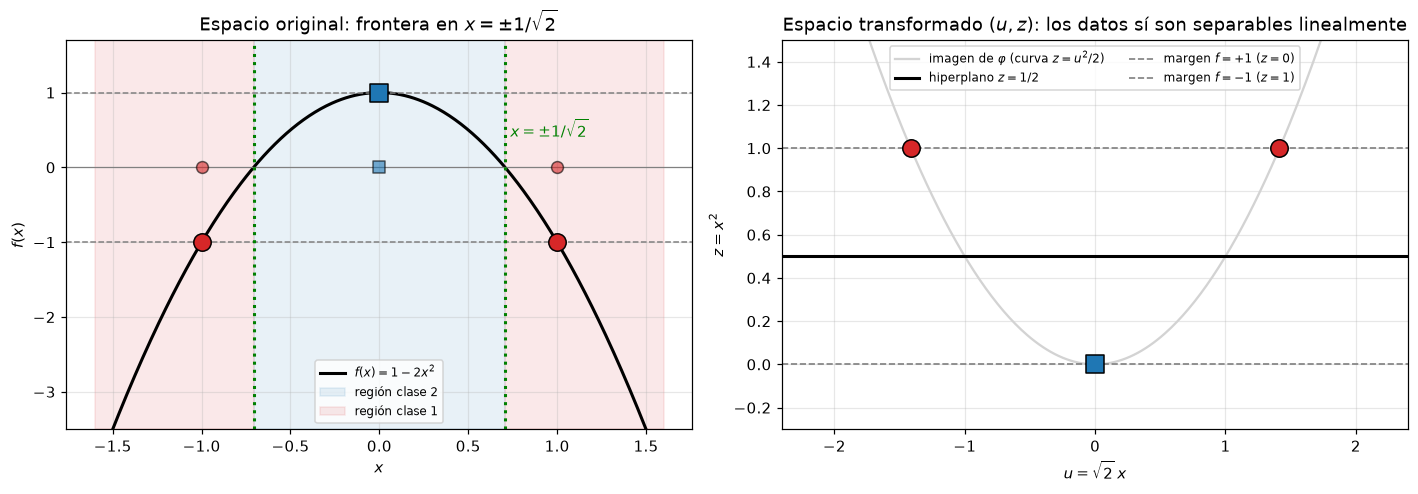

In [7]:
x2 = np.array([-1.0, 0.0, 1.0]); y2 = np.array([-1, 1, -1])
f2 = lambda t: 1 - 2 * t**2
xs = np.linspace(-1.6, 1.6, 500)

fig, axs = plt.subplots(1, 2, figsize=(13, 4.6))

# --- Izquierda: función de decisión en el espacio original
ax = axs[0]
ax.plot(xs, f2(xs), "k", lw=2, label=r"$f(x)=1-2x^2$")
ax.axhline(0, color="gray", lw=0.8); ax.axhline(1, color="gray", ls="--", lw=1); ax.axhline(-1, color="gray", ls="--", lw=1)
r = 1 / np.sqrt(2)
ax.axvspan(-r, r, color=C2, alpha=0.10, label="región clase 2"); 
ax.axvspan(-1.6, -r, color=C1, alpha=0.10); ax.axvspan(r, 1.6, color=C1, alpha=0.10, label="región clase 1")
for v in (-r, r):
    ax.axvline(v, color="green", ls=":", lw=2)
ax.text(r + 0.03, 0.4, r"$x=\pm 1/\sqrt{2}$", color="green")
for xi, yi in zip(x2, y2):
    ax.scatter(xi, f2(xi), marker="o" if yi < 0 else "s", s=130, c=C1 if yi < 0 else C2, edgecolor="k", zorder=4)
    ax.scatter(xi, 0, marker="o" if yi < 0 else "s", s=60, c=C1 if yi < 0 else C2, edgecolor="k", alpha=0.6, zorder=3)
ax.set(xlabel="$x$", ylabel="$f(x)$", ylim=(-3.5, 1.7), title="Espacio original: frontera en $x=\\pm1/\\sqrt{2}$")
ax.legend(loc="lower center", fontsize=8)

# --- Derecha: espacio transformado (√2 x, x²) (la coordenada constante 1 no cambia la geometría)
ax = axs[1]
tt = np.linspace(-1.6, 1.6, 300)
ax.plot(np.sqrt(2) * tt, tt**2, color="lightgray", lw=1.5, label=r"imagen de $\varphi$ (curva $z=u^2/2$)")
for zlev, st, lab in ((0.5, "-", "hiperplano $z=1/2$"), (0.0, "--", "margen $f=+1$ ($z=0$)"), (1.0, "--", "margen $f=-1$ ($z=1$)")):
    ax.axhline(zlev, color="k" if zlev == 0.5 else "gray", ls=st, lw=2 if zlev == 0.5 else 1.1, label=lab)
for xi, yi in zip(x2, y2):
    ax.scatter(np.sqrt(2) * xi, xi**2, marker="o" if yi < 0 else "s", s=130, c=C1 if yi < 0 else C2, edgecolor="k", zorder=4)
ax.set(xlabel=r"$u=\sqrt{2}\,x$", ylabel=r"$z=x^2$", xlim=(-2.4, 2.4), ylim=(-0.3, 1.5), title=r"Espacio transformado $(u,z)$: los datos sí son separables linealmente")
ax.legend(loc="upper center", fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

### Extensión: ¿qué pasa si $C<2$?

Si $C<2$ la solución anterior deja de ser factible ($\alpha_2=2>C$), y el problema pasa a ser realmente de margen blando. Se resuelve de la misma manera: ahora la restricción $\alpha_2=\alpha_1+\alpha_3\le C$ está activa y se maximiza $W$ sobre $\alpha_1+\alpha_3=C$.

Con $p=\alpha_1\alpha_3$ y $\alpha_1^2+\alpha_3^2=C^2-2p$:

$$
W=2C-\tfrac12\big(3(C^2-2p)-2p\big)=2C-\tfrac32C^2+4p ,
$$

que crece con $p$ y, para suma fija $C$, se maximiza en $\alpha_1=\alpha_3=C/2$ (con $p=C^2/4$). Entonces

$$
\alpha=\left(\tfrac C2,\ C,\ \tfrac C2\right),\qquad W=2C-\tfrac12C^2\qquad(0<C\le2).
$$

La función de decisión resulta $f(x)=-\tfrac C2(1-x)^2+C-\tfrac C2(1+x)^2+b=-Cx^2+b$. Las muestras $x_1,x_3$ tienen $0<\alpha<C$ (están en el margen), así que $-f(x_1)=1\Rightarrow C-b=1$, es decir $b=C-1$:

$$
f_C(x)=(C-1)-C\,x^2 .
$$

La muestra central tiene $\alpha_2=C$ (en la cota): $y_2f(0)=C-1\le1$, y por lo tanto **viola el margen** con $\xi_2=1-(C-1)=2-C>0$. Observaciones:

- Para $C=2$ se recupera $f(x)=1-2x^2$ ✓ (con $\xi_2=0$).
- Para $1<C<2$ el clasificador sigue acertando las tres muestras, pero con la muestra central **dentro del margen**; la región de la clase 2 se achica a $|x|<\sqrt{(C-1)/C}$.
- Para $C\le1$, $f_C(0)=C-1\le0$: la muestra de clase 2 queda **mal clasificada** (o justo en la frontera con $C=1$) y $f_C<0$ para todo $x\ne0$: el clasificador predice siempre clase 1.

El gráfico y la verificación siguientes confirman esta deducción.

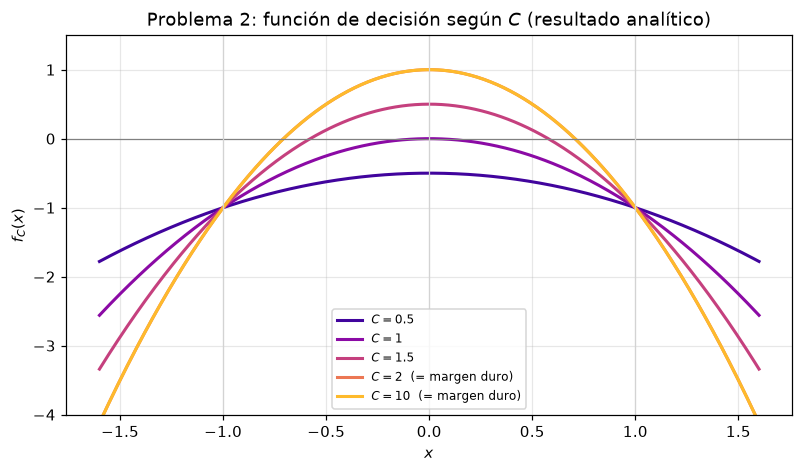

In [8]:
fig, ax = plt.subplots(figsize=(7.4, 4.4))
cols = plt.cm.plasma(np.linspace(0.1, 0.85, 5))
for c_, col in zip([0.5, 1.0, 1.5, 2.0, 10.0], cols):
    Ceff = min(c_, 2.0)          # para C >= 2 la solución es la de margen duro
    ax.plot(xs, (Ceff - 1) - Ceff * xs**2, color=col, lw=2, label=f"$C={c_:g}$" + ("  (= margen duro)" if c_ >= 2 else ""))
ax.axhline(0, color="gray", lw=0.8)
for xi, yi in zip(x2, y2):
    ax.axvline(xi, color="lightgray", lw=0.8)
ax.set(xlabel="$x$", ylabel="$f_C(x)$", ylim=(-4, 1.5), title="Problema 2: función de decisión según $C$ (resultado analítico)")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

**Verificación independiente (no es parte de la resolución).** Se calcula con `scikit-learn` el SVM con núcleo $(x x'+1)^2$ (`kernel="poly", degree=2, gamma=1, coef0=1`) para varios $C$ y se compara con los resultados deducidos: $\alpha=(C/2,C,C/2)$ y $f_C(x)=(C-1)-Cx^2$ para $C\le2$; $\alpha=(1,2,1)$ y $f=1-2x^2$ para $C\ge2$.

In [9]:
print(f"{'C':>5} | {'α (sklearn)':>22} | {'α (analítico)':>22} | {'b sklearn':>9} | {'b analítico':>11} | máx |f - f_analít.|")
for c_ in [0.5, 1.0, 1.5, 2.0, 10.0, 1e4]:
    m = SVC(kernel="poly", degree=2, gamma=1, coef0=1, C=c_, tol=1e-10).fit(x2.reshape(-1, 1), y2)
    alpha = np.zeros(3); alpha[m.support_] = np.abs(m.dual_coef_.ravel())
    Ce = min(c_, 2.0)
    alpha_an = np.array([Ce / 2, Ce, Ce / 2]); b_an = Ce - 1
    f_an = (Ce - 1) - Ce * xs**2
    err = np.abs(m.decision_function(xs.reshape(-1, 1)) - f_an).max()
    print(f"{c_:5g} | {str(alpha.round(4)):>22} | {str(alpha_an.round(4)):>22} | {m.intercept_[0]:9.4f} | {b_an:11.4f} | {err:.2e}")

    C |            α (sklearn) |          α (analítico) | b sklearn | b analítico | máx |f - f_analít.|
  0.5 |       [0.25 0.5  0.25] |       [0.25 0.5  0.25] |   -0.5000 |     -0.5000 | 4.44e-16
    1 |          [0.5 1.  0.5] |          [0.5 1.  0.5] |    0.0000 |      0.0000 | 8.88e-16
  1.5 |       [0.75 1.5  0.75] |       [0.75 1.5  0.75] |    0.5000 |      0.5000 | 1.33e-15
    2 |             [1. 2. 1.] |             [1. 2. 1.] |    1.0000 |      1.0000 | 1.48e-10
   10 |             [1. 2. 1.] |             [1. 2. 1.] |    1.0000 |      1.0000 | 1.48e-10
10000 |             [1. 2. 1.] |             [1. 2. 1.] |    1.0000 |      1.0000 | 1.48e-10


Los $\alpha_i$, el sesgo $b$ y la función de decisión de `scikit-learn` coinciden con los resultados obtenidos a mano para todos los valores de $C$ probados (diferencias del orden de la tolerancia numérica), tanto en el régimen de margen blando ($C<2$) como en el de margen duro ($C\ge2$, con $\alpha=(1,2,1)$ y $f=1-2x^2$).

---
## 4. Conclusiones

1. **Problema 1 (lineal, separable).** Con las tres restricciones $w-b\ge1$, $b\ge1$ y $w+b\ge1$, el dual se reduce a $W=2\alpha_1-\tfrac12(\alpha_1+\alpha_3)^2$ (tras eliminar $\alpha_2$). El máximo está en el borde $\alpha_3=0$: $\alpha=(2,2,0)$, $w=2$, $b=1$ y $f(x)=2x+1$. Los vectores soporte son $x_1=-1$ y $x_2=0$, la frontera es $x=-\tfrac12$ (punto medio entre ellos) y el ancho del margen es 1. El punto $x_3=1$, más alejado de la frontera, no influye en la solución ($\alpha_3=0$). El valor del dual coincide con el del primal ($W=\tfrac12w^2=2$).
2. **Problema 2 (no lineal, núcleo cuadrático).** Con $(xx'+1)^2$ el problema equivale a trabajar con $\varphi(x)=(1,\sqrt2x,x^2)$, donde sí hay un hiperplano separador. Con $K=\begin{pmatrix}4&1&0\\1&1&1\\0&1&4\end{pmatrix}$ se obtiene $\alpha=(1,2,1)$, válido para $C\ge2$, con $f(x)=1-2x^2$: la clase 2 corresponde a $|x|<1/\sqrt2$. Las tres muestras son vectores soporte (todas están sobre los márgenes).
3. **Papel de $C$.** Para $C\ge2$ la solución es la de margen duro; para $C<2$ la muestra central viola el margen ($\alpha_2=C$, $\xi_2=2-C$), $f_C(x)=(C-1)-Cx^2$ y, si $C\le1$, el clasificador deja de acertar esa muestra. Es el compromiso típico de la SVM: $C$ chico ⇒ más tolerancia a errores y márgenes más anchos.
4. **Idea general.** Los vectores soporte son las muestras con $\alpha_i>0$, que quedan sobre el margen (o dentro de él, si $\alpha_i=C$). La solución depende solo de ellas, y con el *kernel trick* se obtienen fronteras no lineales usando únicamente la matriz de Gram.